In [1]:
%run "/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/code/Initialization/Initialization.ipynb"

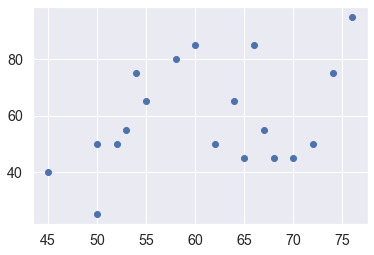

In [2]:
import numpy as np, matplotlib.pyplot as plt

heights = np.array([50,52,53,54,58,60,62,64,66,67,68,70,72,74,76,55,50,45,65])
weights = np.array([25,50,55,75,80,85,50,65,85,55,45,45,50,75,95,65,50,40,45])

plt.plot(heights,weights,'bo')
plt.show()

In [5]:
# Split data into train data(including validation data) and test data
split_ratio = 0.8

data = df_part3.set_index('day')
len_data = df_part3.shape[0]

train_org = df_part3.iloc[:int(len_data*split_ratio),]
test_org = df_part3.iloc[int(len_data*split_ratio):,]

print('train set',train_org.shape)
print('test set',test_org.shape)

train set (250, 22)
test set (63, 22)


# PART 3

In [6]:
df_part3['Num_word'] = df_part3['Articles'].apply(lambda x:len(str(x).split())) #Number Of words in main text

KeyError: 'Articles'

In [ ]:
df_part3['Num_word'].plot(figsize=(20, 10),title='Number of words')

# FULL DATA

In [ ]:
df['Num_word'] = df['Articles'].apply(lambda x:len(str(x).split())) #Number Of words in main text

In [ ]:
df['Num_word'].plot(figsize=(20, 10),title='Number of words')

In [ ]:
plt.figure(figsize=(12,6))
p1=sns.kdeplot(df['Num_word'], shade=True, color="r").set_title('Kernel Distribution of Number Of words')
# p1=sns.kdeplot(train['Num_word_text'], shade=True, color="b")

In [ ]:
def clean_text(text):
    '''Make text lowercase, remove text in square brackets,remove links,remove punctuation
    and remove words containing numbers.'''
    text = str(text).lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

In [ ]:
df['articles'] = df['Articles'].apply(lambda x:clean_text(x))

In [ ]:
df.head()


In [ ]:
from collections import Counter
df['temp_list'] = df['articles'].apply(lambda x:str(x).split())
top = Counter([item for sublist in df['temp_list'] for item in sublist])
temp = pd.DataFrame(top.most_common(200))
temp.columns = ['Common_words','count']
temp.style.background_gradient(cmap='Blues')

In [ ]:
import plotly.express as px
fig = px.bar(temp, x="count", y="Common_words", title='Commmon Words in Text', orientation='h', 
             width=700, height=700,color='Common_words')
fig.show()

In [ ]:
fig = px.bar(temp, x="count", y="Common_words", title='Commmon Words in Text', orientation='h', 
             width=700, height=700,color='Common_words')
fig.show()

# Addintions

In [ ]:
class TextCounts(BaseEstimator, TransformerMixin):
    
    def count_regex(self, pattern, tweet):
        return len(re.findall(pattern, tweet))
    
    def fit(self, X, y=None, **fit_params):
        # fit method is used when specific operations need to be done on the train data, but not on the test data
        return self
    
    def transform(self, X, **transform_params):
        count_words = X.apply(lambda x: self.count_regex(r'\w+', x)) 
        count_mentions = X.apply(lambda x: self.count_regex(r'@\w+', x))
        count_hashtags = X.apply(lambda x: self.count_regex(r'#\w+', x))
        count_capital_words = X.apply(lambda x: self.count_regex(r'\b[A-Z]{2,}\b', x))
        count_excl_quest_marks = X.apply(lambda x: self.count_regex(r'!|\?', x))
        count_urls = X.apply(lambda x: self.count_regex(r'http.?://[^\s]+[\s]?', x))
        # Moreover, it will result in having more words in the tweet
        
        df = pd.DataFrame({'count_words': count_words
                           , 'count_mentions': count_mentions
                           , 'count_hashtags': count_hashtags
                           , 'count_capital_words': count_capital_words
                           , 'count_excl_quest_marks': count_excl_quest_marks
                           , 'count_urls': count_urls
                          })
        
        return df

In [ ]:
tc = TextCounts()
#df_eda = tc.fit_transform(df_vix.articles)


In [ ]:
def show_dist(df, col):
    print('Descriptive stats for {}'.format(col))
    print('-'*(len(col)+22))
    print(df.groupby('VIX')[col].describe())
    bins = np.arange(df[col].min(), df[col].max() + 1)
    g = sns.FacetGrid(df, col='VIX', size=5, hue='VIX', palette="PuBuGn_d")
    g = g.map(sns.distplot, col, kde=False, norm_hist=True, bins=bins)
    plt.show()

In [ ]:
#df_vixs=df[['VIX']]
target_dist = sns.factorplot(x="Hour", data=df_hour_part3, kind="count", size=10, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIX_Histogram.png')

In [ ]:
#df[['sentiment']])#.add(0.5).round().apply(int).options.display.float_format = '{:,.0f}'.format
#round()
df[['sentiment']] = pd.to_numeric(df['sentiment'])

In [ ]:
df[['sentiment']].round()

In [ ]:
target_dist = sns.factorplot(x="sentiment", data=df[['sentiment']].round(0), kind="count", size=15, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/sentiment_Histogram.png')